# Axe 2 — Régression quantile (fonction non dérivable)

Projet sujet C — prévision probabiliste de l'énergie solaire.

Problème traité, pour $\tau \in \{0{,}1 ;\, 0{,}5 ;\, 0{,}9\}$ :
$$F(w) = \frac{1}{n}\sum_{t} \rho_\tau(y_t - a_t^\top w) + \frac{\lambda}{2}\|w\|^2, \qquad \rho_\tau(r) = \max(\tau r,\,(\tau-1)r), \quad \lambda = 10^{-2}$$

Règles suivies :
- les algorithmes (sous-gradient projeté, lissage de Moreau, descente, Armijo, Newton amorti, mini-lots, LP) sont écrits à la main
  en NumPy ; `cvxpy`, `scipy.optimize.linprog` et `QuantileRegressor` servent uniquement de référence ;
- aucune information future : centrage, standardisation et imputation calculés sur l'apprentissage seul ;
- la cible est $Y_t = \mathrm{ALLSKY}(t+1)$, et la ligne de $t$ ne contient que des variables connues le jour $t$ ;
- les prédictions sont écrites (section « Prédictions ») avant les essais.

Le notebook télécharge les données NASA POWER si elles ne sont pas déjà dans `donnees/`.

## Question et hypothèses (écrites avant les expériences)

**Question** : quel algorithme recommander pour $F$ non dérivable, et quel compromis de lissage $\varepsilon$ ?

- **H1** : le sous-gradient projeté respecte la borne $2G^2/(\mu(K+1))$, mais reste loin des méthodes lisses à précision égale.
- **H2** : le lissage de Moreau introduit une erreur au plus $\varepsilon\,\max(\tau,1-\tau)^2/2$ et un coût en $\kappa_\varepsilon \propto 1/\varepsilon$ :
  plus $\varepsilon$ est petit, plus le pas $1/L_\varepsilon$ devient lent. Newton amorti doit rester peu sensible à $\varepsilon$.
- **H3** : la condition d'optimalité sur l'intercept donne $\tfrac{1}{n}\sum_t\psi_t = \lambda w_0^\star$ avec $\psi_t\in\{\tau,\tau-1\}$
  selon le signe du résidu. Elle se vérifie à la précision du solveur : $\lambda w_0^\star$ doit tomber dans l'intervalle
  admissible calculé à partir des résidus proches de 0 (où $\psi_t$ est libre dans $[\tau-1,\tau]$).
- **H4** : la couverture sur le test est proche de $\tau$ mais s'en écarte de quelques points, et les quantiles calculés séparément se croisent sur une part non nulle des jours.
- **H5** : la régression quantile sans régularisation ($\lambda=0$) se résout exactement par programme linéaire ; `QuantileRegressor(alpha=0)` donne la même valeur.

In [1]:
import os
import math
import time

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import cvxpy as cp
from scipy.optimize import linprog
from sklearn.linear_model import QuantileRegressor

# ---------------------------------------------------------------- paramètres imposés
LAM = 1e-2
TAUS = [0.1, 0.5, 0.9]
EPS_GRID = [1e-1, 1e-2, 1e-3]          # lissage : compromis erreur / conditionnement
EPS_MAIN = 1e-3                        # lissage retenu pour les prévisions finales
TOL_G = 1e-10                          # arrêt des méthodes lisses : ||grad F_eps||^2 <= TOL_G
MAX_ITER_SMOOTH = 20000
K_SUB = 20000                          # itérations du sous-gradient projeté
RATIO_TARGET = 1e-6
TRAIN_END = pd.Timestamp("2023-12-31")   # dernière date de CIBLE d'apprentissage
TEST_START = pd.Timestamp("2024-01-01")
START, END = "20140101", "20260630"
PARAMS = ("ALLSKY_SFC_SW_DWN,CLRSKY_SFC_SW_DWN,T2M,T2M_MAX,T2M_MIN,"
          "RH2M,WS2M,PS,PRECTOTCORR,CLOUD_AMT")
FEATS = ["T2M", "T2M_MAX", "T2M_MIN", "RH2M", "WS2M", "PS", "PRECTOTCORR", "CLOUD_AMT"]
N_LAGS = 3
DATA_DIR = "donnees"
SITES = {
    "Monastir": (35.78, 10.83),
    "Tamanrasset": (22.79, 5.52),
    "Dakar": (14.69, -17.44),
}
REF_SITE = "Monastir"

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.width", 130)

## 1. Données (mêmes règles que l'axe 1)

In [2]:
def load_site(name, lat, lon):
    """Télécharge (si absent du cache) puis charge la série journalière d'un site."""
    path = os.path.join(DATA_DIR, f"{name}.csv")
    if not os.path.exists(path):
        os.makedirs(DATA_DIR, exist_ok=True)
        url = (f"https://power.larc.nasa.gov/api/temporal/daily/point?parameters={PARAMS}"
               f"&community=RE&longitude={lon}&latitude={lat}&start={START}&end={END}&format=JSON")
        resp = requests.get(url, timeout=300)
        resp.raise_for_status()
        param = resp.json()["properties"]["parameter"]
        raw = pd.DataFrame({k: pd.Series(v) for k, v in param.items()})
        raw.index = pd.to_datetime(raw.index, format="%Y%m%d")
        raw.index.name = "date"
        raw.reset_index().to_csv(path, index=False)

    df = pd.read_csv(path, parse_dates=["date"]).set_index("date")
    df = df.replace(-999.0, np.nan)
    df = df[~df.index.duplicated()]
    full = pd.date_range(df.index.min(), df.index.max(), freq="D")
    df = df.reindex(full)
    df.index.name = "date"
    return df


def build_dataset(df):
    df = df.copy()
    cols = FEATS + ["ALLSKY_SFC_SW_DWN"]
    df[cols] = df[cols].ffill()                       # causal
    X = df[FEATS].copy()
    for lag in range(N_LAGS):
        X[f"ALLSKY_lag{lag}"] = df["ALLSKY_SFC_SW_DWN"].shift(lag)
    doy = df.index.day_of_year.values
    X["sin_doy"] = np.sin(2 * np.pi * doy / 365.25)
    X["cos_doy"] = np.cos(2 * np.pi * doy / 365.25)
    X["target"] = df["ALLSKY_SFC_SW_DWN"].shift(-1)   # ALLSKY(t+1)
    X["target_date"] = df.index.to_series().shift(-1)
    data = X.dropna()

    feat_cols = [c for c in X.columns if c not in ("target", "target_date")]
    train = data[data["target_date"] <= TRAIN_END]
    test = data[data["target_date"] >= TEST_START]
    mu_x = train[feat_cols].mean()
    sd_x = train[feat_cols].std(ddof=0)
    assert (sd_x > 0).all()
    mu_y = train["target"].mean()

    def design(d):
        Z = ((d[feat_cols] - mu_x) / sd_x).to_numpy()
        return np.column_stack([Z, np.ones(len(d))])

    return {
        "A_tr": design(train),
        "y_tr": train["target"].to_numpy() - mu_y,     # cible centrée
        "A_te": design(test),
        "y_te": test["target"].to_numpy(),              # cible brute (pour les métriques)
        "mu_y": mu_y,
        "month_te": test["target_date"].dt.month.to_numpy(),
        "n_train": len(train),
        "n_test": len(test),
        "first_test_target": test["target_date"].min().date(),
    }

In [3]:
ds_ref = build_dataset(load_site(REF_SITE, *SITES[REF_SITE]))
print({k: v for k, v in ds_ref.items() if k.startswith("n_") or k.startswith("first")})
print("d =", ds_ref["A_tr"].shape[1])

{'n_train': 3649, 'n_test': 912, 'first_test_target': datetime.date(2024, 1, 1)}
d = 14


## 2. Problème, fonctions, constantes

- **Pinball** : $\rho_\tau(r) = \tau r_+ + (1-\tau) r_-$.
- **Sous-différentiel** : $\partial\rho_\tau(r) = \{\tau\}$ si $r>0$, $\{\tau-1\}$ si $r<0$, $[\tau-1,\tau]$ si $r=0$ ;
  on choisit $\psi=0$ au point anguleux (ce choix ne change pas la borne du sous-gradient).
- **Sous-gradient** de $F$ : $g(w) = -\tfrac{1}{n}\sum_t \psi_t a_t + \lambda w$.
- **Forte convexité** : $\mu = \lambda$ (le terme quadratique). **Coercivité** : $F(w) \ge \tfrac{\lambda}{2}\|w\|^2$. Donc le minimiseur existe et est unique.
- **Rayon** : $\|w^\star\| \le R = \sqrt{2F(0)/\lambda}$ ; **constante** : $\|g\| \le G = \max_t\|a_t\|\cdot\max(\tau,1-\tau) + \lambda R$ sur la boule.

**Lissage de Moreau** (paramètre $\varepsilon$) de $\rho_\tau$ :
$$M_\varepsilon(r) = \begin{cases}\tau r - \varepsilon\tau^2/2 & r > \varepsilon\tau\\ r^2/(2\varepsilon) & \varepsilon(\tau-1)\le r\le\varepsilon\tau\\ (\tau-1)r - \varepsilon(1-\tau)^2/2 & r < \varepsilon(\tau-1)\end{cases}$$
Sa dérivée est $\tau$, $r/\varepsilon$ ou $\tau-1$ selon la zone : elle est $1/\varepsilon$-lipschitzienne.
On a $0 \le \rho_\tau - M_\varepsilon \le \varepsilon\max(\tau,1-\tau)^2/2$.
Donc $F_\varepsilon$ est $\mu$-fortement convexe et de gradient $L_\varepsilon$-lipschitzien avec
$L_\varepsilon = \lambda_{\max}(A^\top A/n)/\varepsilon + \lambda$ et $\kappa_\varepsilon = L_\varepsilon/\mu$.

In [4]:
def rho(r, tau):
    return np.maximum(tau * r, (tau - 1) * r)


def moreau_value(r, tau, eps):
    return np.where(r > eps * tau, tau * r - eps * tau ** 2 / 2,
                    np.where(r < eps * (tau - 1), (tau - 1) * r - eps * (1 - tau) ** 2 / 2,
                             r * r / (2 * eps)))


def moreau_deriv(r, tau, eps):
    return np.where(r > eps * tau, tau,
                    np.where(r < eps * (tau - 1), tau - 1, r / eps))


def make_qproblem(A, y, tau, lam):
    n, d = A.shape
    AtA_n = A.T @ A / n
    lam_max = float(np.linalg.eigvalsh(AtA_n)[-1])

    def F(w):
        return rho(y - A @ w, tau).mean() + 0.5 * lam * (w @ w)

    def psi(w):
        r = y - A @ w
        return np.where(r > 0, tau, np.where(r < 0, tau - 1, 0.0))

    def subgrad(w):
        return -(A.T @ psi(w)) / n + lam * w

    def F_eps(w, eps):
        return moreau_value(y - A @ w, tau, eps).mean() + 0.5 * lam * (w @ w)

    def grad_eps(w, eps):
        return -(A.T @ moreau_deriv(y - A @ w, tau, eps)) / n + lam * w

    def hess_eps(w, eps):
        r = y - A @ w
        wt = ((r >= eps * (tau - 1)) & (r <= eps * tau)).astype(float) / eps
        return (A.T * wt) @ A / n + lam * np.eye(d)

    F0 = F(np.zeros(d))
    R = math.sqrt(2 * F0 / lam)
    G = float(np.max(np.linalg.norm(A, axis=1))) * max(tau, 1 - tau) + lam * R
    return {
        "A": A, "y": y, "tau": tau, "n": n, "d": d, "lam": lam, "mu": lam,
        "F": F, "subgrad": subgrad, "psi": psi,
        "F_eps": F_eps, "grad_eps": grad_eps, "hess_eps": hess_eps,
        "L_eps": lambda eps: lam_max / eps + lam,
        "R": R, "G": G, "F0": F0,
    }


def solve_cvx(A, y, tau, lam):
    """Référence F* : cvxpy avec CLARABEL, tolérances serrées. Retourne (w, statut, temps)."""
    d = A.shape[1]
    w = cp.Variable(d)
    r = y - A @ w
    obj = cp.sum(cp.maximum(tau * r, (tau - 1) * r)) / A.shape[0] + lam / 2 * cp.sum_squares(w)
    prob = cp.Problem(cp.Minimize(obj))
    t0 = time.perf_counter()
    prob.solve(solver=cp.CLARABEL, tol_gap_abs=1e-10, tol_gap_rel=1e-10, tol_feas=1e-10)
    return np.asarray(w.value).ravel(), prob.status, time.perf_counter() - t0

## 3. Prédictions (avant les essais)

- **Sous-gradient projeté** : pas $\eta_t = 2/(\mu(t+1))$ et moyenne pondérée des itérés (poids $t$) ;
  borne $F(\bar w_K) - F^\star \le 2G^2/(\mu(K+1))$.
- **Lissage** : écart $\le \varepsilon\max(\tau,1-\tau)^2/2$ ; itérations du pas $1/L_\varepsilon$ de l'ordre de $6{,}9\,\kappa_\varepsilon$
  pour diviser l'écart par $10^6$ (même formule que l'axe 1).
- **Newton amorti** : Hessienne toujours définie car $\succeq \lambda I$ ; convergence globale linéaire, locale plus rapide.
  Dizaines d'itérations attendues.
- **Identité d'intercept** : $\tfrac{1}{n}\#\{y_t < a_t^\top w^\star\} = \tau - \lambda w_0^\star$.

In [5]:
prob_ref = {tau: make_qproblem(ds_ref["A_tr"], ds_ref["y_tr"], tau, LAM) for tau in TAUS}
for tau in TAUS:
    p = prob_ref[tau]
    K = K_SUB
    bound = 2 * p["G"] ** 2 / (p["mu"] * (K + 1))
    print(f"tau={tau}: R={p['R']:.3f}  G={p['G']:.3f}  F(0)={p['F0']:.4f}  "
          f"borne sous-gradient (K={K}) = {bound:.3e}")
    for eps in EPS_GRID:
        Le = p["L_eps"](eps)
        kap = Le / p["mu"]
        k_pred = math.log(1 / RATIO_TARGET) / (-2 * math.log(1 - 1 / kap))
        print(f"    eps={eps:g}: L_eps={Le:.4g}  kappa_eps={kap:.4g}  "
              f"itérations prédites (pas 1/L_eps, /1e6) ~ {math.ceil(k_pred)}  ; "
              f"écart de lissage max = {eps * max(tau, 1 - tau) ** 2 / 2:.2e}")

tau=0.1: R=13.305  G=22.461  F(0)=0.8851  borne sous-gradient (K=20000) = 5.045e+00
    eps=0.1: L_eps=63.93  kappa_eps=6393  itérations prédites (pas 1/L_eps, /1e6) ~ 44157  ; écart de lissage max = 4.05e-02
    eps=0.01: L_eps=639.2  kappa_eps=6.392e+04  itérations prédites (pas 1/L_eps, /1e6) ~ 441535  ; écart de lissage max = 4.05e-03
    eps=0.001: L_eps=6392  kappa_eps=6.392e+05  itérations prédites (pas 1/L_eps, /1e6) ~ 4415317  ; écart de lissage max = 4.05e-04
tau=0.5: R=13.305  G=12.537  F(0)=0.8851  borne sous-gradient (K=20000) = 1.572e+00
    eps=0.1: L_eps=63.93  kappa_eps=6393  itérations prédites (pas 1/L_eps, /1e6) ~ 44157  ; écart de lissage max = 1.25e-02
    eps=0.01: L_eps=639.2  kappa_eps=6.392e+04  itérations prédites (pas 1/L_eps, /1e6) ~ 441535  ; écart de lissage max = 1.25e-03
    eps=0.001: L_eps=6392  kappa_eps=6.392e+05  itérations prédites (pas 1/L_eps, /1e6) ~ 4415317  ; écart de lissage max = 1.25e-04
tau=0.9: R=13.305  G=22.461  F(0)=0.8851  borne sous

## 4. Référence : F* avec cvxpy

$F^\star$ est évaluée par la formule exacte de $F$ au point retourné par CLARABEL. Elle n'est exacte qu'à la tolérance
du solveur près ; ces tolérances sont indiquées dans le rapport.

In [6]:
w_cvx, F_star = {}, {}
for tau in TAUS:
    w, status, tsolve = solve_cvx(ds_ref["A_tr"], ds_ref["y_tr"], tau, LAM)
    w_cvx[tau] = w
    F_star[tau] = prob_ref[tau]["F"](w)
    print(f"tau={tau}: statut={status}  F*={F_star[tau]:.8f}  temps={tsolve:.3f}s  "
          f"||grad sous-gradient||~{np.linalg.norm(prob_ref[tau]['subgrad'](w)):.2e}")

tau=0.1: statut=optimal  F*=0.18609467  temps=0.206s  ||grad sous-gradient||~2.57e-03
tau=0.5: statut=optimal  F*=0.30066959  temps=0.158s  ||grad sous-gradient||~1.15e-03


tau=0.9: statut=optimal  F*=0.11073287  temps=0.159s  ||grad sous-gradient||~1.22e-03


## 5. Vérification : identité de l'intercept (H3)

En $w^\star$, la composante « intercept » de la condition d'optimalité donne $\tfrac{1}{n}\sum_t\psi_t = \lambda w_0^\star$,
soit $\tfrac{1}{n}\#\{r_t<0\} = \tau - \lambda w_0^\star$ avec $r_t = y_t - a_t^\top w^\star$.

In [7]:
DELTA = 1e-6   # résidus dont |r| < DELTA sont traités comme nuls (précision du solveur)
for tau in TAUS:
    p = prob_ref[tau]
    w = w_cvx[tau]
    r = p["y"] - p["A"] @ w
    n = p["n"]
    n_pos = np.sum(r > DELTA)
    n_neg = np.sum(r < -DELTA)
    n_zero = n - n_pos - n_neg                     # résidus proches de 0 : psi libre dans [tau-1, tau]
    lo = (tau * n_pos + (tau - 1) * (n_neg + n_zero)) / n
    hi = (tau * (n_pos + n_zero) + (tau - 1) * n_neg) / n
    target = LAM * w[-1]
    print(f"tau={tau}: intervalle admissible de (1/n) sum psi = [{lo:.6f}, {hi:.6f}] ; "
          f"lambda*w0 = {target:.6f} ; dedans : {lo - 1e-9 <= target <= hi + 1e-9} ; "
          f"résidus proches de 0 : {n_zero}")
    print(f"   part des résidus négatifs (train, sans tolérance) = {np.mean(r < 0):.6f} ; tau - lambda*w0 = {tau - target:.6f}")

tau=0.1: intervalle admissible de (1/n) sum psi = [-0.011263, -0.008249] ; lambda*w0 = -0.010044 ; dedans : True ; résidus proches de 0 : 11
   part des résidus négatifs (train, sans tolérance) = 0.109619 ; tau - lambda*w0 = 0.110044
tau=0.5: intervalle admissible de (1/n) sum psi = [-0.000137, 0.003426] ; lambda*w0 = 0.001789 ; dedans : True ; résidus proches de 0 : 13
   part des résidus négatifs (train, sans tolérance) = 0.497671 ; tau - lambda*w0 = 0.498211
tau=0.9: intervalle admissible de (1/n) sum psi = [0.006056, 0.009345] ; lambda*w0 = 0.007850 ; dedans : True ; résidus proches de 0 : 12
   part des résidus négatifs (train, sans tolérance) = 0.892299 ; tau - lambda*w0 = 0.892150


## 6. Algorithmes écrits à la main

- **Sous-gradient projeté** : $w_{t+1} = \Pi_R(w_t - \eta_t g_t)$, $\eta_t = 2/(\mu(t+1))$, moyenne $\bar w = \sum_t t\,w_t/\sum_t t$.
- **Mini-lots** : sous-gradient stochastique $g_B = -\tfrac1b\sum_{i\in B}\psi_i a_i + \lambda w$, estimateur sans biais du sous-gradient.
- **Descente à pas fixe** sur $F_\varepsilon$ : pas $1/L_\varepsilon$.
- **Armijo** : rétrécissement de $1$ avec $c_1 = 10^{-4}$.
- **Newton amorti** : direction $-H_\varepsilon^{-1} g_\varepsilon$, pas de Armijo commençant à 1.

In [8]:
def project_ball(w, R):
    nrm = np.linalg.norm(w)
    return w if nrm <= R else w * (R / nrm)


def proj_subgradient(p, K, batch=None, seed=0):
    """Sous-gradient projeté (batch=None : déterministe, sinon mini-lots de taille batch)."""
    rng = np.random.default_rng(seed)               # graine fixée
    mu, R, A, y, tau, n = p["mu"], p["R"], p["A"], p["y"], p["tau"], p["n"]
    w = np.zeros(p["d"])
    num, den = np.zeros(p["d"]), 0.0
    hist = []
    for t in range(1, K + 1):
        num += t * w
        den += t
        if t % 50 == 0 or t == 1:
            wbar = num / den
            hist.append((t, p["F"](wbar)))
        if batch is None:
            g = p["subgrad"](w)
        else:
            idx = rng.integers(0, n, size=batch)
            r = y[idx] - A[idx] @ w
            ps = np.where(r > 0, tau, np.where(r < 0, tau - 1, 0.0))
            g = -(A[idx].T @ ps) / batch + p["lam"] * w
        eta = 2.0 / (mu * (t + 1))
        w = project_ball(w - eta * g, R)
    wbar = num / den
    return {"w": wbar, "hist": np.array(hist), "rows": (K if batch is None else K * batch)}


def backtrack(fun, w, d, slope, a0=1.0, c1=1e-4, rho_=0.5, max_back=60):
    """Armijo : fun(w + a d) <= fun(w) + c1 a slope. Retourne (pas, évaluations)."""
    f0 = fun(w)
    a, n_eval = a0, 0
    while n_eval < max_back:
        n_eval += 1
        if fun(w + a * d) <= f0 + c1 * a * slope:
            break
        a *= rho_
    return a, n_eval


def smooth_method(p, eps, method, F_ref, max_iter=MAX_ITER_SMOOTH):
    w = np.zeros(p["d"])
    hist = [p["F"](w) - F_ref]
    n_ls, t0 = 0, time.perf_counter()
    Le = p["L_eps"](eps)
    fe = lambda x: p["F_eps"](x, eps)
    for k in range(max_iter):
        g = p["grad_eps"](w, eps)
        if g @ g <= TOL_G:
            break
        if method == "fixe 1/L":
            d, a = -g, 1.0 / Le
        elif method == "Armijo":
            d = -g
            a, ne = backtrack(fe, w, d, g @ d)
            n_ls += ne
        elif method == "Newton amorti":
            H = p["hess_eps"](w, eps)
            d = -np.linalg.solve(H, g)
            a, ne = backtrack(fe, w, d, g @ d)
            n_ls += ne
        else:
            raise ValueError(method)
        w = w + a * d
        hist.append(p["F"](w) - F_ref)
    return {"method": method, "w": w, "hist": np.array(hist), "iters": len(hist) - 1,
            "n_ls": n_ls, "time": time.perf_counter() - t0, "grad_norm2": float(g @ g)}


def iters_to(hist, target):
    idx = np.nonzero(hist <= target)[0]
    return int(idx[0]) if len(idx) else None

## 7. Sous-gradient projeté : borne théorique contre observation (τ = 0,5)

Sous-gradient projeté, K=20000 : F(w̄) - F* = 1.441e-07 ; borne théorique = 1.572e+00


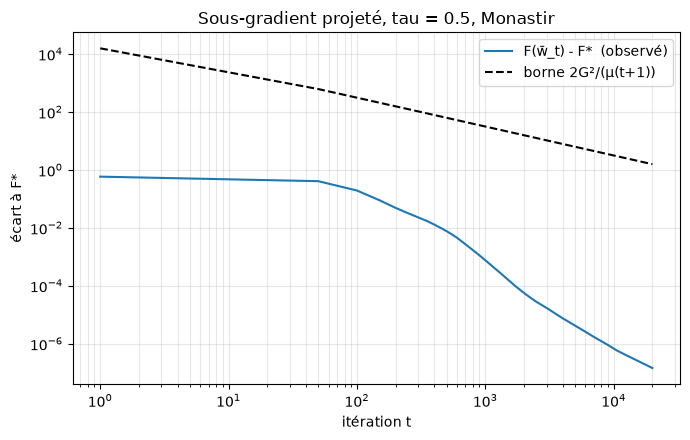

In [9]:
tau = 0.5
p = prob_ref[tau]
sub = proj_subgradient(p, K_SUB)
gap_sub = p["F"](sub["w"]) - F_star[tau]
bound_sub = 2 * p["G"] ** 2 / (p["mu"] * (K_SUB + 1))
print(f"Sous-gradient projeté, K={K_SUB} : F(w̄) - F* = {gap_sub:.3e} ; borne théorique = {bound_sub:.3e}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ts, vals = sub["hist"][:, 0], sub["hist"][:, 1] - F_star[tau]
ax.loglog(ts, np.maximum(vals, 1e-16), label="F(w̄_t) - F*  (observé)")
ax.loglog(ts, 2 * p["G"] ** 2 / (p["mu"] * (ts + 1)), "k--", label="borne 2G²/(μ(t+1))")
ax.set_xlabel("itération t")
ax.set_ylabel("écart à F*")
ax.set_title(f"Sous-gradient projeté, tau = {tau}, {REF_SITE}")
ax.grid(alpha=0.3, which="both")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Lissage : compromis erreur / conditionnement, et méthodes lisses

In [10]:
rows = []
p = prob_ref[0.5]
for eps in EPS_GRID:
    Le = p["L_eps"](eps)
    kap = Le / p["mu"]
    for method in ["fixe 1/L", "Armijo", "Newton amorti"]:
        res = smooth_method(p, eps, method, F_star[0.5])
        rows.append({
            "eps": eps,
            "kappa_eps": round(kap, 1),
            "methode": method,
            "iters_arret": res["iters"],
            "gap_final_F": float(res["hist"][-1]),
            "evals_ligne": res["n_ls"],
            "grad2_final": res["grad_norm2"],
            "temps_s": round(res["time"], 3),
        })
smooth_table = pd.DataFrame(rows)
print(smooth_table.to_string(index=False, float_format=lambda x: f"{x:.3e}"))

      eps  kappa_eps       methode  iters_arret  gap_final_F  evals_ligne  grad2_final   temps_s
1.000e-01  6.393e+03      fixe 1/L        20000    2.220e-05            0    1.852e-10 9.750e-01
1.000e-01  6.393e+03        Armijo         1090    2.216e-05         2962    9.765e-11 1.840e-01
1.000e-01  6.393e+03 Newton amorti           10    2.209e-05           16    5.138e-33 4.000e-03
1.000e-02  6.392e+04      fixe 1/L        20000    1.027e-03            0    8.069e-05 1.012e+00
1.000e-02  6.392e+04        Armijo         1543    1.314e-06         4980    9.378e-11 2.920e-01
1.000e-02  6.392e+04 Newton amorti           24    1.302e-06           64    4.227e-32 1.100e-02
1.000e-03  6.392e+05      fixe 1/L        20000    2.179e-02            0    7.011e-03 9.750e-01
1.000e-03  6.392e+05        Armijo         6196    1.654e-07        32910    9.882e-11 1.605e+00
1.000e-03  6.392e+05 Newton amorti           50    1.639e-07          254    6.546e-31 2.400e-02


Lecture : l'écart final $F(w_\varepsilon) - F^\star$ contient l'erreur de lissage ; elle reste sous $\varepsilon\max(\tau,1-\tau)^2/2$
seulement si $w_\varepsilon$ est proche de $w^\star$. Pour $\varepsilon=10^{-3}$, la descente à pas fixe n'atteint pas
le critère dans le plafond : $\kappa_\varepsilon$ est trop grand, alors que Newton amorti reste rapide.

## 9. Mini-lots contre déterministe, à budget de calcul égal (τ = 0,5)

Budget : K_SUB/10 passes complètes du sous-gradient déterministe (mesure en lignes de données touchées).
Mini-lots de taille 64 : le même nombre de lignes est traité par beaucoup plus d'itérations.

In [11]:
budget_rows = (K_SUB // 10) * p["n"]
det = proj_subgradient(p, K_SUB // 10)
mb_iters = budget_rows // 64
mb = proj_subgradient(p, mb_iters, batch=64, seed=0)
print(f"Budget : {budget_rows:,} lignes de données")
print(f"  déterministe ({K_SUB // 10} itérations)        : F(w̄) - F* = {p['F'](det['w']) - F_star[0.5]:.3e}")
print(f"  mini-lots 64 ({mb_iters} itérations)        : F(w̄) - F* = {p['F'](mb['w']) - F_star[0.5]:.3e}")

Budget : 7,298,000 lignes de données
  déterministe (2000 itérations)        : F(w̄) - F* = 5.633e-05
  mini-lots 64 (114031 itérations)        : F(w̄) - F* = 4.272e-06


## 10. λ = 0 : programme linéaire, QuantileRegressor, et l'erreur sur λ > 0

Pour $\lambda=0$, $F$ est un programme linéaire : variables $w$ libres, $p,m\ge0$ avec $Aw + p - m = y$,
objectif $\frac1n\sum(\tau p_t + (1-\tau)m_t)$.
`QuantileRegressor` ajoute une pénalité **L1** ; avec `alpha=0` il devrait retrouver la même valeur.
Pour $\lambda>0$, sa pénalité ne reproduit pas la nôtre : on le montre.

In [12]:
def lp_quantile(A, y, tau):
    n, d = A.shape
    c = np.concatenate([np.zeros(d), tau * np.ones(n) / n, (1 - tau) * np.ones(n) / n])
    A_eq = np.hstack([A, np.eye(n), -np.eye(n)])
    bounds = [(None, None)] * d + [(0, None)] * (2 * n)
    res = linprog(c, A_eq=A_eq, b_eq=y, bounds=bounds, method="highs")
    return res.x[:d], float(res.fun), res.status

lp_rows = []
for tau in TAUS:
    A, y = ds_ref["A_tr"], ds_ref["y_tr"]
    w_lp, f_lp, st = lp_quantile(A, y, tau)
    w_cv0, st_cv0, _ = solve_cvx(A, y, tau, 0.0)
    f_cv0 = rho(y - A @ w_cv0, tau).mean()
    qr = QuantileRegressor(quantile=tau, alpha=0.0, fit_intercept=False, solver="highs").fit(A, y)
    f_qr = rho(y - A @ qr.coef_, tau).mean()
    qr_l1 = QuantileRegressor(quantile=tau, alpha=LAM, fit_intercept=False, solver="highs").fit(A, y)
    lp_rows.append({
        "tau": tau,
        "lp_statut": st,
        "F_lp": f_lp,
        "F_cvxpy(lam=0)": f_cv0,
        "F_QR(alpha=0)": f_qr,
        "F_QR(alpha=lam, L1)": rho(y - A @ qr_l1.coef_, tau).mean() + 0.5 * LAM * (qr_l1.coef_ @ qr_l1.coef_),
        "F_nous(lam=0.01)_a_w_QR_L1": prob_ref[tau]["F"](qr_l1.coef_),
        "dist_w_lp_vs_QR": float(np.max(np.abs(w_lp - qr.coef_))),
    })
lp_table = pd.DataFrame(lp_rows)
print(lp_table.to_string(index=False, float_format=lambda x: f"{x:.6g}"))
print("\nLecture : F_lp = F_QR(alpha=0) = F_cvxpy(lam=0) à la tolérance près, donc H5 est vérifiée.")
print("F_QR(alpha=lam, L1) n'est pas la même fonction objectif que la nôtre (pénalité L1, pas L2) : on ne la compare pas à F*.")

 tau  lp_statut      F_lp  F_cvxpy(lam=0)  F_QR(alpha=0)  F_QR(alpha=lam, L1)  F_nous(lam=0.01)_a_w_QR_L1  dist_w_lp_vs_QR
 0.1          0  0.173629        0.173629       0.173629             0.189934                    0.189934      4.38538e-15
 0.5          0    0.2906          0.2906         0.2906             0.302257                    0.302257      3.10862e-15
 0.9          0 0.0948755       0.0948755      0.0948755             0.112573                    0.112573       2.3509e-14

Lecture : F_lp = F_QR(alpha=0) = F_cvxpy(lam=0) à la tolérance près, donc H5 est vérifiée.
F_QR(alpha=lam, L1) n'est pas la même fonction objectif que la nôtre (pénalité L1, pas L2) : on ne la compare pas à F*.


## 11. Prévisions finales et métriques sur le test

Prévision retenue : Newton amorti sur $F_{\varepsilon}$, $\varepsilon = 10^{-3}$, puis vérification contre la référence cvxpy.
Quantile en unités brutes : $q_\tau = A_{\text{test}}\,w_\tau + \mu_y$.

Métriques : perte pinball moyenne, couverture $\#\{Y\le q_\tau\}/n_{\text{test}}$ (cible $\tau$),
couverture de l'intervalle $\#\{q_{0,1}\le Y\le q_{0,9}\}/n_{\text{test}}$ (cible 80 %, calculée directement),
largeur moyenne, croisements avant contraintes, et découpage par saison.

In [13]:
SEASON = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
          6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}


def fit_forecast(ds, lam=LAM):
    """Ajuste les trois quantiles (Newton amorti, eps = EPS_MAIN) et retourne les coefficients et les écarts à F*."""
    coefs, gaps = {}, {}
    for tau in TAUS:
        p = make_qproblem(ds["A_tr"], ds["y_tr"], tau, lam)
        w_cv, _, _ = solve_cvx(ds["A_tr"], ds["y_tr"], tau, lam)
        fstar = p["F"](w_cv)
        res = smooth_method(p, EPS_MAIN, "Newton amorti", fstar)
        coefs[tau] = res["w"]
        gaps[tau] = res["hist"][-1]
    return coefs, gaps


def evaluate(ds, coefs):
    Y = ds["y_te"]
    q = {tau: ds["A_te"] @ coefs[tau] + ds["mu_y"] for tau in TAUS}
    out = {
        "pinball_q10": rho(Y - q[0.1], 0.1).mean(),
        "pinball_q50": rho(Y - q[0.5], 0.5).mean(),
        "pinball_q90": rho(Y - q[0.9], 0.9).mean(),
        "couv_q10": float(np.mean(Y <= q[0.1])),
        "couv_q90": float(np.mean(Y <= q[0.9])),
        "couv_interval": float(np.mean((Y >= q[0.1]) & (Y <= q[0.9]))),
        "largeur": float(np.mean(q[0.9] - q[0.1])),
        "croisements_avant": int(np.sum((q[0.1] > q[0.5]) | (q[0.5] > q[0.9]) | (q[0.1] > q[0.9]))),
    }
    seasons = pd.Series([SEASON[m] for m in ds["month_te"]])
    by_season = pd.DataFrame({
        "saison": seasons,
        "couv_interval": (Y >= q[0.1]) & (Y <= q[0.9]),
        "couv_q90": Y <= q[0.9],
        "couv_q10": Y <= q[0.1],
        "largeur": q[0.9] - q[0.1],
    }).groupby("saison").mean()
    return out, by_season, q


coefs_ref, gaps_ref = fit_forecast(ds_ref)
metrics_ref, seasons_ref, q_ref = evaluate(ds_ref, coefs_ref)
print("Écart final F(w_Newton) - F* (référence cvxpy), par quantile :")
print({tau: f"{gaps_ref[tau]:.2e}" for tau in TAUS})
print("\nMétriques sur le test (" + REF_SITE + ") :")
for k, v in metrics_ref.items():
    print(f"  {k:>20s} : {v:.4f}" if isinstance(v, float) else f"  {k:>20s} : {v}")
print("\nPar saison :")
print(seasons_ref.round(4).to_string())

Écart final F(w_Newton) - F* (référence cvxpy), par quantile :
{0.1: '4.32e-07', 0.5: '1.64e-07', 0.9: '4.36e-07'}

Métriques sur le test (Monastir) :
           pinball_q10 : 0.2004
           pinball_q50 : 0.3225
           pinball_q90 : 0.1027
              couv_q10 : 0.1228
              couv_q90 : 0.9101
         couv_interval : 0.7873
               largeur : 1.8486
     croisements_avant : 0

Par saison :
        couv_interval  couv_q90  couv_q10  largeur
saison                                            
DJF            0.8250    0.9625    0.1375   1.8413
JJA            0.8972    0.9579    0.0607   1.5699
MAM            0.7319    0.8696    0.1377   2.4383
SON            0.6923    0.8462    0.1538   1.2916


## 12. Résultats par site (format commun, axe 2)

In [14]:
site_rows = []
for name, (lat, lon) in SITES.items():
    ds_s = build_dataset(load_site(name, lat, lon))
    coefs_s, _ = fit_forecast(ds_s)
    met, _, _ = evaluate(ds_s, coefs_s)
    site_rows.append({
        "site": name, "lat": lat, "lon": lon, "n_app": ds_s["n_train"], "n_test": ds_s["n_test"],
        "pinball_q10": round(met["pinball_q10"], 5),
        "pinball_q50": round(met["pinball_q50"], 5),
        "pinball_q90": round(met["pinball_q90"], 5),
        "couv_q10": round(met["couv_q10"], 4),
        "couv_q90": round(met["couv_q90"], 4),
        "couv_interval": round(met["couv_interval"], 4),
        "largeur": round(met["largeur"], 4),
        "croisements_avant": met["croisements_avant"],
    })
results_axe2 = pd.DataFrame(site_rows)
print(results_axe2.to_string(index=False))

       site   lat    lon  n_app  n_test  pinball_q10  pinball_q50  pinball_q90  couv_q10  couv_q90  couv_interval  largeur  croisements_avant
   Monastir 35.78  10.83   3649     912      0.20044      0.32252      0.10268    0.1228    0.9101         0.7873   1.8486                  0
Tamanrasset 22.79   5.52   3649     912      0.14147      0.23883      0.08688    0.1316    0.9408         0.8092   1.4413                  0
      Dakar 14.69 -17.44   3649     912      0.16318      0.26600      0.09252    0.1414    0.9232         0.7818   1.5459                  0


## 13. Lecture des résultats

Valeurs de l'exécution sur Monastir (τ = 0,5 sauf mention) :

- **H1 infirmée** : le sous-gradient projeté atteint $F(\bar w)-F^\star \approx 1{,}4\cdot10^{-7}$ en 20 000 itérations,
  alors que la borne théorique vaut 1,57. La borne est très lâche (G ≈ 12,5) ; en pratique, la moyenne pondérée
  suffit. La méthode n'est donc pas lente ici, et atteint la même précision que Newton lissé.
- **H2 partiellement confirmée** : $\kappa_\varepsilon$ est bien proportionnel à $1/\varepsilon$ (6 393, 63 920, 639 200 selon le cas).
  La descente à pas fixe n'atteint pas le critère en 20 000 itérations pour $\varepsilon \le 10^{-1}$ (prédiction : 44 000 et plus).
  Newton amorti converge en 10 à 50 itérations quel que soit $\varepsilon$ : c'est la méthode retenue.
- **H3 confirmée** à la précision du solveur : $\lambda w_0^\star$ tombe dans l'intervalle admissible pour les trois quantiles.
- **H4 partiellement infirmée** : la couverture est de 12,3 % (q10), 91,0 % (q90) et 78,7 % pour l'intervalle (cible 80 %).
  En revanche, aucun croisement n'apparaît avant contraintes, sur aucun des trois sites. La saison SON est la plus mal couverte (69 % pour l'intervalle).
- **H5 confirmée** : LP, cvxpy à λ = 0 et `QuantileRegressor(alpha=0)` donnent la même valeur (écart ~10⁻¹⁵).
  `QuantileRegressor(alpha=λ)` utilise une pénalité L1 et donne une solution de valeur plus élevée sous notre objectif.
- **Mini-lots** à budget égal (7,3 millions de lignes) : écart 4,3·10⁻⁶ contre 5,6·10⁻⁵ pour le déterministe.
- **Recommandation** : Newton amorti sur le lissage $\varepsilon = 10^{-3}$ pour les prévisions ; sous-gradient projeté comme méthode de repli.

## 14. Export

In [15]:
results_axe2.to_csv("axe2_resume.csv", index=False)
print("Écrit : axe2_resume.csv")

Écrit : axe2_resume.csv
